# imports

In [155]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from model_utils import export_model_data_json, get_auc_roc
from preprocess import get_data
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

In [156]:
new_df = get_data()
new_df

,VITESSE_MA,METEO_beau,METEO_chute de neige,METEO_couvert,METEO_grêle,METEO_pluie,METEO_pluie givrante,ETAT_ROUTE_enneigée,ETAT_ROUTE_humide,ETAT_ROUTE_mouillé,ETAT_ROUTE_neige fondante,ETAT_ROUTE_route enneigée,ETAT_ROUTE_sèche,ETAT_ROUTE_verglacée,HEURE_SIN,HEURE_COS,VICTIME
0,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.866,-0.500,False
1,80.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.000,-1.000,False
2,50.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.707,0.707,False
3,50.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.000,0.000,False
4,80.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.866,-0.500,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18586,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.259,-0.966,False
18587,120.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.707,0.707,False
18588,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.259,-0.966,False
18589,50.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.500,-0.866,False


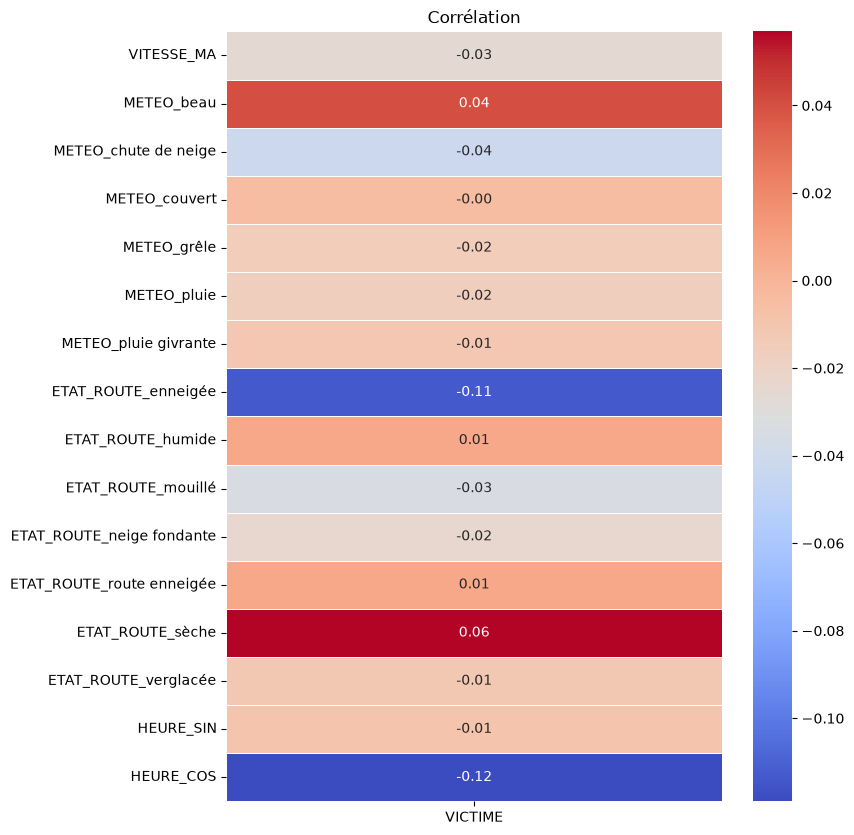

In [157]:
# Toutes les colonnes sauf les targets pour les lignes
feature_cols = [col for col in new_df.columns if col not in "VICTIME"]
corr = new_df.corr().loc[feature_cols, "VICTIME"]
corr = corr.to_frame(name="VICTIME")

plt.figure(figsize=(8, 10))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    cbar=True,
)
plt.title("Corrélation", fontsize=12)
plt.show()

# model

In [158]:
# hyperparameters
LEARNING_RATE = 1e-3
EPOCHS = 200
HIDDEN_SIZES = [32, 64, 64, 64, 32, 8]
DROPOUT_RATE = 0.1
BATCH_SIZE = 453 * 2

# constants
INPUT_SIZE = new_df.shape[1] - 1
OUTPUT_SIZE = 1
ACCURACY_LOOP = 30

# Hyperparamters grids search
param_grid = {
    "hidden_sizes": [[30, 30], [64, 64], [128, 128]],
    "dropout_rate": [0.1, 0.2, 0.3, 0.5],
    "learning_rate": [1e-2, 1e-3, 1e-4, 1e-5],
    "batch_size": [64, 256, 512, 1024, 2048, 4096],
    "epochs": [300],
}

print(INPUT_SIZE)

16


In [167]:
X_train, X_temp, y_train, y_temp = train_test_split(
    new_df.drop(columns=["VICTIME"]),
    new_df[["VICTIME"]],
    test_size=0.2,
    random_state=42,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print(new_df.shape)
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

counts = y_train["VICTIME"].value_counts()
print(f"neg: {counts[False] / X_train.shape[0] * 100:.1f}%")
print(f"pos: {counts[True] / X_train.shape[0] * 100:.1f}%")

train_dataloader = DataLoader(
    TensorDataset(
        torch.tensor(X_train.values, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_dataloader = DataLoader(
    TensorDataset(
        torch.tensor(X_val.values, dtype=torch.float32),
        torch.tensor(y_val.values, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_dataloader = DataLoader(
    TensorDataset(
        torch.tensor(X_test.values, dtype=torch.float32),
        torch.tensor(y_test.values, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)


(18116, 17)
(14492, 16)
(1812, 16)
(1812, 16)
neg: 53.8%
pos: 46.2%


In [160]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout_rate):
        super(MLP, self).__init__()

        layers = []

        # input layer
        layers.append(nn.Linear(input_size, hidden_sizes[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(dropout_rate))

        # hidden layers
        for i in range(len(hidden_sizes) - 1):
            layers.append(nn.Linear(hidden_sizes[i], hidden_sizes[i + 1]))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))

        # output layer
        layers.append(nn.Linear(hidden_sizes[-1], output_size))

        # combine all layers
        self.model = nn.Sequential(*layers)

    def forward(self, x):  # type: ignore
        return self.model(x)


In [161]:
def train(dataloader, model, loss_fn, optimizer):
    model.train()
    train_loss = 0.0

    for X, y in dataloader:
        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)
        train_loss += loss.item()

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

    return train_loss / len(dataloader)


def test(dataloader, model, loss_fn):
    model.eval()
    test_loss = 0.0
    all_targets = []
    all_preds = []
    all_scores = []

    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            loss = loss_fn(pred, y)
            test_loss += loss.item()
            all_targets.append(y.int())
            all_preds.append((pred > 0.5).int())
            all_scores.append(pred)

    targets = torch.cat(all_targets).numpy().ravel()
    preds = torch.cat(all_preds).numpy().ravel()
    scores = torch.cat(all_scores).numpy().ravel()
    fpr, tpr, _ = roc_curve(targets, scores)
    tn, fp, fn, tp = confusion_matrix(y_true=targets, y_pred=preds).ravel().tolist()

    print(f"\t acc = {accuracy_score(targets, preds) * 100:.1f}%")
    print(f"\t tn = {tn}, fp = {fp}, fn = {fn}, tp = {tp}")
    print(f"\t pres = {precision_score(targets, preds) * 100:.1f}%")
    print(f"\t recall = {recall_score(y_true=targets, y_pred=preds) * 100:.1f}%")
    print(f"\t f1  = {f1_score(targets, preds):.3f}")
    print(f"\t auc = {auc(fpr, tpr):.3f}")

    return test_loss / len(dataloader), targets, scores


In [162]:
model = MLP(INPUT_SIZE, HIDDEN_SIZES, OUTPUT_SIZE, DROPOUT_RATE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.BCEWithLogitsLoss()

In [163]:
train_losses = []
validation_losses = []

for t in range(EPOCHS):
    print(f"epoch {t + 1}/{EPOCHS} ")

    train_loss = train(train_dataloader, model, loss_fn, optimizer)
    validation_loss, _, _ = test(val_dataloader, model, loss_fn)

    train_losses.append(train_loss)
    validation_losses.append(validation_loss)

    # print(f"\t train loss: {train_loss:.4f}")
    # print(f"\t validation loss: {validation_loss:.4f}")


epoch 1/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.520
epoch 2/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.523
epoch 3/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.518
epoch 4/200 


/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` par

	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.517
epoch 5/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.517
epoch 6/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.572
epoch 7/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.568
epoch 8/200 


/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` par

	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.553
epoch 9/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.588
epoch 10/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.574
epoch 11/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.568
epoch 12/200 


...

	 acc = 54.1%
	 tn = 940, fp = 33, fn = 799, tp = 40
	 pres = 54.8%
	 recall = 4.8%
	 f1  = 0.088
	 auc = 0.618
epoch 139/200 
	 acc = 53.7%
	 tn = 973, fp = 0, fn = 839, tp = 0
	 pres = 0.0%
	 recall = 0.0%
	 f1  = 0.000
	 auc = 0.615
epoch 140/200 
	 acc = 55.4%
	 tn = 903, fp = 70, fn = 739, tp = 100
	 pres = 58.8%
	 recall = 11.9%
	 f1  = 0.198
	 auc = 0.619
epoch 141/200 
	 acc = 55.4%
	 tn = 900, fp = 73, fn = 735, tp = 104
	 pres = 58.8%
	 recall = 12.4%
	 f1  = 0.205
	 auc = 0.617
epoch 142/200 


/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


	 acc = 56.0%
	 tn = 864, fp = 109, fn = 689, tp = 150
	 pres = 57.9%
	 recall = 17.9%
	 f1  = 0.273
	 auc = 0.621
epoch 143/200 
	 acc = 54.0%
	 tn = 954, fp = 19, fn = 814, tp = 25
	 pres = 56.8%
	 recall = 3.0%
	 f1  = 0.057
	 auc = 0.619
epoch 144/200 
	 acc = 55.2%
	 tn = 900, fp = 73, fn = 738, tp = 101
	 pres = 58.0%
	 recall = 12.0%
	 f1  = 0.199
	 auc = 0.620
epoch 145/200 
	 acc = 55.2%
	 tn = 921, fp = 52, fn = 760, tp = 79
	 pres = 60.3%
	 recall = 9.4%
	 f1  = 0.163
	 auc = 0.622
epoch 146/200 
	 acc = 54.5%
	 tn = 939, fp = 34, fn = 790, tp = 49
	 pres = 59.0%
	 recall = 5.8%
	 f1  = 0.106
	 auc = 0.621
epoch 147/200 
	 acc = 55.4%
	 tn = 889, fp = 84, fn = 724, tp = 115
	 pres = 57.8%
	 recall = 13.7%
	 f1  = 0.222
	 auc = 0.624
epoch 148/200 
	 acc = 54.5%
	 tn = 939, fp = 34, fn = 790, tp = 49
	 pres = 59.0%
	 recall = 5.8%
	 f1  = 0.106
	 auc = 0.625
epoch 149/200 
	 acc = 54.8%
	 tn = 906, fp = 67, fn = 752, tp = 87
	 pres = 56.5%
	 recall = 10.4%
	 f1  = 0.175
	 auc

/Users/mov/Documents/hei/2026-2027/sem1/hackathon/sos-routier/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


	 acc = 55.7%
	 tn = 873, fp = 100, fn = 702, tp = 137
	 pres = 57.8%
	 recall = 16.3%
	 f1  = 0.255
	 auc = 0.623
epoch 156/200 
	 acc = 53.9%
	 tn = 972, fp = 1, fn = 834, tp = 5
	 pres = 83.3%
	 recall = 0.6%
	 f1  = 0.012
	 auc = 0.623
epoch 157/200 
	 acc = 54.2%
	 tn = 931, fp = 42, fn = 787, tp = 52
	 pres = 55.3%
	 recall = 6.2%
	 f1  = 0.111
	 auc = 0.617
epoch 158/200 
	 acc = 55.4%
	 tn = 914, fp = 59, fn = 750, tp = 89
	 pres = 60.1%
	 recall = 10.6%
	 f1  = 0.180
	 auc = 0.624
epoch 159/200 
	 acc = 53.6%
	 tn = 969, fp = 4, fn = 836, tp = 3
	 pres = 42.9%
	 recall = 0.4%
	 f1  = 0.007
	 auc = 0.616
epoch 160/200 
	 acc = 55.5%
	 tn = 917, fp = 56, fn = 750, tp = 89
	 pres = 61.4%
	 recall = 10.6%
	 f1  = 0.181
	 auc = 0.624
epoch 161/200 
	 acc = 54.0%
	 tn = 954, fp = 19, fn = 814, tp = 25
	 pres = 56.8%
	 recall = 3.0%
	 f1  = 0.057
	 auc = 0.624
epoch 162/200 
	 acc = 55.0%
	 tn = 921, fp = 52, fn = 764, tp = 75
	 pres = 59.1%
	 recall = 8.9%
	 f1  = 0.155
	 auc = 0.61

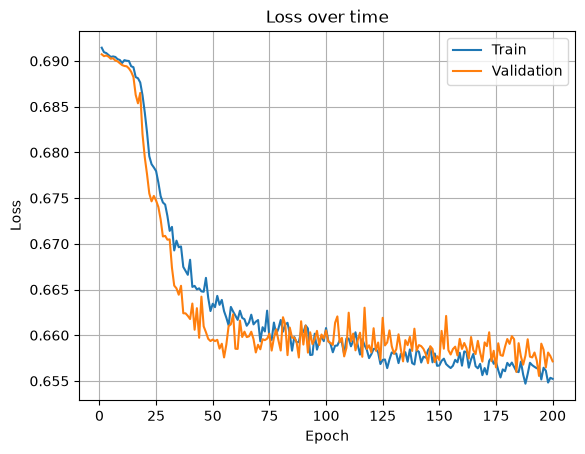

In [164]:
epoch_numbers = range(1, EPOCHS + 1)
plt.plot(epoch_numbers, train_losses, label="Train")
plt.plot(epoch_numbers, validation_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over time")
plt.legend()
plt.grid(True)
plt.show()

In [170]:
_, y_test, y_proba_test = test(test_dataloader, model, loss_fn)
_auc, _roc = get_auc_roc(y_test, y_proba_test)
export_model_data_json("mlp", _auc, _roc)

	 acc = 58.1%
	 tn = 921, fp = 97, fn = 663, tp = 131
	 pres = 57.5%
	 recall = 16.5%
	 f1  = 0.256
	 auc = 0.627
